In [3]:
import os
import sys

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["MASSIVE_TOKEN"] = "jsnt7igBpyyAduX4WGdDEuw0gStWNVFk"
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)
import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient


def test():

    ticker = "SPY"
    d = date(2024, 1, 3)
    client = MassiveClient()
    option_ticker = "O:SPY240105P00470000"

    def package(ticker, verbose=Context.all):

        with verbose.write_t(
            f"Fetching OCV, trades, quotes for {ticker} on {fmt_date(d)}... ", end=""
        ) as tme:
            ocv = client.fetch_day_summary(ticker, d, adjusted=True)
            verbose.write(f"done: found {fmt_dict(ocv)}. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching trades for {ticker} on {fmt_date(d)}... ", end="") as tme:
            trades = client.fetch_trades(ticker, d)
            verbose.write(f"done: found {len(trades)} trades. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching quotes for {ticker} on {fmt_date(d)}... ", end="") as tme:
            quotes = client.fetch_quotes(ticker, d)
            verbose.write(f"done: found {len(quotes)} quotes. This took {tme}.", head=False)

        return ocv, trades, quotes

    package(ticker)
    ocv, trades, quotes = package(option_ticker)

    display(ocv)
    display(trades.head())
    display(quotes.head())


test()

00: Fetching OCV, trades, quotes for SPY on 2024-01-03... done: found open: 470.43, close: 468.79, volume: 103577866.0, high: 471.19, low: 468.17, afterHours: 469.35, preMarket: 472.07 and adjusted: True. This took 0.704ms.
00: Fetching trades for SPY on 2024-01-03... done: found 656589 trades. This took 6.12ms.
00: Fetching quotes for SPY on 2024-01-03... done: found 4927896 quotes. This took 0.021s.
00: Fetching OCV, trades, quotes for O:SPY240105P00470000 on 2024-01-03... done: found open: 1.67, close: 2.38, volume: 69357.0, high: 2.71, low: 1.25, afterHours: 2.43, preMarket: 1.67 and adjusted: True. This took 1.19ms.
00: Fetching trades for O:SPY240105P00470000 on 2024-01-03... done: found 8895 trades. This took 1.88ms.
00: Fetching quotes for O:SPY240105P00470000 on 2024-01-03... done: found 85145 quotes. This took 4.45ms.


/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


{'open': 1.67,
 'close': 2.38,
 'volume': 69357.0,
 'high': 2.71,
 'low': 1.25,
 'afterHours': 2.43,
 'preMarket': 1.67,
 'adjusted': True}

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256


ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.217322240 EST,1.72,46.0,1.74,46.0
2024-01-03 09:30:00.383298048 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.400694528 EST,1.69,2.0,1.8,36.0
2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0


In [4]:
option_ticker = "O:SPY240105P00470000"
client = MassiveClient()
df_trades = client.fetch_trades(option_ticker, date(2024, 1, 3))
df_quotes = client.fetch_quotes(option_ticker, date(2024, 1, 3))

In [5]:
import matplotlib.pyplot as plt

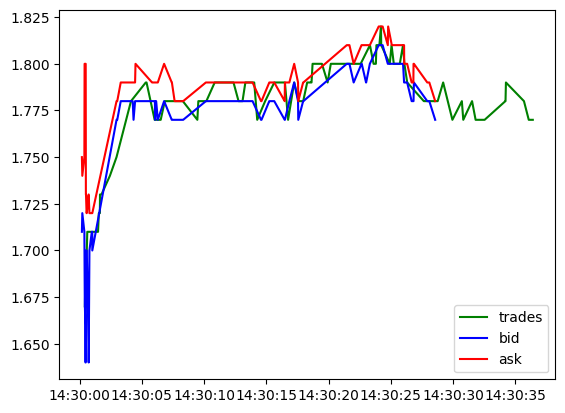

In [8]:
N = 100
plt.plot(df_trades["ts_ns"].head(N), df_trades["price"].head(N), label="trades", color="green")
plt.plot(df_quotes["ts_ns"].head(N), df_quotes["bid_price"].head(N), label="bid", color="blue")
plt.plot(df_quotes["ts_ns"].head(N), df_quotes["ask_price"].head(N), label="ask", color="red")
plt.legend()
plt.show()

In [13]:
import plotly.graph_objects as go

N = 10000
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=df_trades["ts_ns"],
        y=df_trades["price"],
        mode="markers",
        name="trades",
        marker=dict(color="green", size=8),
    )
)
fig.add_trace(
    go.Scatter(
        x=df_quotes["ts_ns"],
        y=df_quotes["bid_price"],
        mode="lines",
        name="bid",
        line=dict(color="blue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=df_quotes["ts_ns"],
        y=df_quotes["ask_price"],
        mode="lines",
        name="ask",
        line=dict(color="red"),
    )
)
fig.show()